# 06 Producción: modelos estadísticos y de aprendizaje automático

Pregunta: qué modelo concreto y qué hiperparámetros ocupan las familias estadística y de aprendizaje automático del tablero, y cómo se comportan en un año que no vieron.

Decisión que sustenta: el ganador de cada familia (entre ARIMA, SARIMA y Prophet-AR, y entre XGBoost y LightGBM), sus hiperparámetros y los dos paquetes que se suben al tablero.

Sigue las secciones 2, 4 a 8 y 10 de METODOLOGIA_PRONOSTICO.md con el código de pronóstico del tablero (pathologies/dengue/pronostico): la serie, las clases de los modelos, la prueba 85/15, las métricas y la exportación son las del tablero, así que lo que se evalúa aquí es exactamente lo que el tablero ejecuta. Resultados en outputs/resultados/06_resultados.json, que lee el notebook 07.

## Decisiones que vienen de la investigación

Este notebook no vuelve a discutir el diseño del pronóstico: lo aplica. Las decisiones fijas y el notebook que las sustenta:

| Decisión heredada | Notebook de origen |
|---|---|
| Definición de caso (códigos 210 y 220) y depuración de los microdatos, que aplica el pipeline de limpieza del tablero | 01 |
| log1p(casos) como escala de trabajo de ARIMA, SARIMA, Prophet-AR y las redes, y como opción de los árboles | 03 |
| Entradas autorregresivas: rezagos de casos, con 1, 2, 4 y 8 semanas como punto de partida, y ventana de semanas para las redes, con 12 de partida | 03 |
| Estacionalidad anual de 52 semanas | 03 |
| Tres familias candidatas: estadística, aprendizaje automático y aprendizaje profundo | 03 |
| Evaluación multipaso de 1 a 6 semanas con origen móvil, porque a un paso los modelos no se distinguen | 03 |
| Sin variables climáticas: su aporte en el rango operativo no compensa el costo de mantener las series | 05 |

El agrupamiento de municipios (04) caracteriza el territorio y no entra en el pronóstico; la fuente climática por variable (02) no aplica porque el pronóstico no usa clima. Lo que se decide aquí, con esas decisiones fijas, es el modelo concreto de cada familia y sus hiperparámetros, en la serie que el tablero pronostica y con su propio código.

In [1]:
import getpass
import os
import sys
from pathlib import Path

# Modo rapido: 3 pruebas de Optuna por modelo y un corte de validacion cruzada. Sirve para
# comprobar que el notebook corre de punta a punta; sus salidas van a subcarpetas _rapido.
MODO_RAPIDO = True
if "MODO_RAPIDO" in os.environ:
    MODO_RAPIDO = os.environ["MODO_RAPIDO"] == "1"

# Unica ruta al repositorio del tablero (o variable de entorno RUTA_TABLERO).
RUTA_TABLERO = os.environ.get("RUTA_TABLERO", r"C:\Users\edavi\PROYECTOS\public-health-surveillance-system")
USUARIO_TABLERO = os.environ.get("USUARIO_TABLERO", getpass.getuser())

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from dengue import experimentacion as ex

ex.preparar_entorno_determinista()
from dengue import produccion as pr

RUTA_TABLERO = pr.preparar_tablero(RUTA_TABLERO)
SALIDAS = ex.configurar_salidas("produccion_estadisticos_ml", MODO_RAPIDO)
FIGURAS = ex.RegistroFiguras(SALIDAS, "06")
CRONO = ex.Cronometro()
CRONO.etapa("serie")
print("Modo rapido:", MODO_RAPIDO)
print("Tablero:", RUTA_TABLERO)
print("Figuras:", SALIDAS.figuras)
print("Resultados:", SALIDAS.resultados)

Modo rapido: False
Tablero: C:\Users\elias\pruebas-eddie\public-health-surveillance-system
Figuras: C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\outputs\figures\produccion_estadisticos_ml
Resultados: C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\outputs\resultados


## 1 Serie del tablero y periodos

construir_serie_semanal_departamental sobre el consolidado del tablero: casos notificados (códigos 210 y 220, probables y confirmados) por semana epidemiológica CDC, de 2007 a 2025. La prueba usa la serie recortada a 2007-2024; 2025 se reserva para la prueba final.

In [2]:
import shutil
import tempfile
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

import prophet  # noqa: F401  (para silenciar cmdstanpy antes del primer ajuste)
from dengue import investigacion as inv
from pathologies.dengue.pronostico import evaluacion, paquete
from pathologies.dengue.pronostico.manifest import ORIGEN_SUBIDO

warnings.filterwarnings('ignore')
ex.silenciar_registros()
inv.silenciar_prophet()
ex.estilo_figuras()

SERIES = pr.cargar_series(RUTA_TABLERO)
SERIE = SERIES['serie']                 # 2007 a 2025
SERIE_2024 = SERIES['serie_2024']       # 2007 a 2024
SEMANAS_2024 = SERIES['semanas_2024']
PERIODOS = pr.periodos(SERIE_2024)
N85 = PERIODOS['fin_entrenamiento']
SERIE_ENTRENAMIENTO = SERIE_2024.iloc[:N85].reset_index(drop=True)

print(f"Serie: {len(SERIE)} semanas, {SERIE['fecha_semana'].iloc[0].date()} a {SERIE['fecha_semana'].iloc[-1].date()}")
display(pd.DataFrame([
    {'Periodo': 'Entrenamiento (85 %)', 'Desde': PERIODOS['fechas']['inicio'], 'Hasta (exclusive)': PERIODOS['fechas']['inicio_prueba'], 'Semanas': N85},
    {'Periodo': 'Prueba (15 %)', 'Desde': PERIODOS['fechas']['inicio_prueba'],
     'Hasta (exclusive)': str(SERIE['fecha_semana'].iloc[SEMANAS_2024].date()), 'Semanas': PERIODOS['semanas'] - N85},
    {'Periodo': 'Prueba final 2025', 'Desde': SERIE['fecha_semana'].iloc[SEMANAS_2024].date(), 'Hasta (exclusive)': '', 'Semanas': len(SERIE) - SEMANAS_2024},
]))

Serie: 992 semanas, 2006-12-31 a 2025-12-28


,Periodo,Desde,Hasta (exclusive),Semanas
0,Entrenamiento (85 %),2006-12-31,2022-04-17,798
1,Prueba (15 %),2022-04-17,2024-12-29,141
2,Prueba final 2025,2024-12-29,,53


Comprobación: los registros walk-forward que este notebook arma para la validación cruzada y para 2025 (experimentacion.construir_registros) son idénticos a los de evaluacion.evaluar_en_prueba del tablero.

In [3]:
Arima = pr.clase_modelo('arima')
oficial = evaluacion.evaluar_en_prueba(Arima, None, SERIE_2024)['registros']
modelo = Arima(None)
modelo.entrenar(SERIE_ENTRENAMIENTO)
propio = pr.evaluar_en_bloque(modelo, SERIE_2024, N85, len(SERIE_2024) - 1)
assert len(oficial) == len(propio)
assert (oficial['fecha_objetivo'].values == propio['fecha_objetivo'].values).all()
assert np.allclose(oficial['pronostico_modelo'], propio['pronostico_modelo'])
print(f'Registros identicos: {len(propio)} ({len(propio) // 6} semanas de prueba x 6 horizontes)')

Registros identicos: 846 (141 semanas de prueba x 6 horizontes)


## 2 Validación cruzada dentro del entrenamiento

Tres cortes sucesivos dentro del 85 %. Cada corte aplica evaluar_en_prueba del tablero a la serie que termina en él: entrena con su primer 85 % y evalúa su 15 % final. Los bloques evaluados son contiguos, no se solapan y cubren años de baja transmisión y los brotes de 2018 y 2019. Optuna minimiza el promedio del RMSE global (H1 a H6) de los tres cortes y registra el MAE.

In [4]:
CORTES = ex.cortes_validacion_cruzada(N85)
if MODO_RAPIDO:
    CORTES = CORTES[-1:]
fechas = SERIE_2024['fecha_semana']
display(pd.DataFrame([{'Corte': i + 1, 'Entrena hasta': fechas.iloc[k['inicio_bloque'] - 1].date(),
                       'Evalúa desde': fechas.iloc[k['inicio_bloque']].date(),
                       'Evalúa hasta': fechas.iloc[k['fin_bloque'] - 1].date(),
                       'Semanas evaluadas': k['fin_bloque'] - k['inicio_bloque']} for i, k in enumerate(CORTES)]))
N_PRUEBAS = pr.PRUEBAS_RAPIDO if MODO_RAPIDO else pr.PRUEBAS
ESTUDIOS = {}
CANDIDATOS = {}


def buscar(clave, espacio, aic=None):
    clase = pr.clase_modelo(clave)
    estudio = ex.crear_estudio(f'06_{clave}')
    objetivo = pr.objetivo_validacion_cruzada(clase, espacio, SERIE_ENTRENAMIENTO, CORTES, aic=aic)
    estudio.optimize(objetivo, n_trials=N_PRUEBAS[clave], gc_after_trial=True)
    historial = ex.guardar_historial(estudio, SALIDAS, f'06_{clave}')
    ESTUDIOS[clave] = estudio
    mejor = estudio.best_trial
    CANDIDATOS[clave] = {
        'nombre': clase.nombre, 'familia': clase.familia,
        'hiperparametros': {**clase.hiperparametros_por_defecto, **mejor.user_attrs['hiperparametros']},
        'optuna': {**ex.resumen_estudio(estudio), 'historial': historial},
        'validacion_cruzada': {'rmse': mejor.value, 'mae': mejor.user_attrs['mae'],
                               'rmse_cortes': mejor.user_attrs['rmse_cortes'], 'mae_cortes': mejor.user_attrs['mae_cortes']},
    }
    print(f"{clase.nombre}: RMSE validacion cruzada = {mejor.value:.3f} | MAE = {mejor.user_attrs['mae']:.3f}")
    print('  hiperparametros:', mejor.user_attrs['hiperparametros'])
    return estudio


print('Pruebas de Optuna por modelo:', N_PRUEBAS)

,Corte,Entrena hasta,Evalúa desde,Evalúa hasta,Semanas evaluadas
0,1,2016-05-15,2016-05-22,2018-01-07,86
1,2,2018-01-07,2018-01-14,2019-12-22,102
2,3,2019-12-22,2019-12-29,2022-04-10,120


Pruebas de Optuna por modelo: {'arima': 30, 'sarima': 25, 'prophet_ar': 40, 'xgboost': 80, 'lightgbm': 80, 'lstm': 30, 'nbeats': 30}


## 3 Búsqueda de hiperparámetros

Optuna con el muestreador TPE y semilla fija. Los espacios solo incluyen hiperparámetros que acepta cada clase del tablero (hiperparametros_por_defecto); los que no se buscan quedan en su valor por defecto. Las combinaciones repetidas que propone TPE en los espacios discretos no se vuelven a entrenar.

### 3.1 Diferenciación de ARIMA y SARIMA

In [5]:
CRONO.etapa('busqueda_estadisticos')
DIFERENCIACION = ex.diferenciaciones(np.log1p(SERIE_ENTRENAMIENTO['casos'].to_numpy(dtype=float)))
display(pd.DataFrame(DIFERENCIACION['pruebas_regulares']).round(4))
D_ESTACIONAL = DIFERENCIACION['D']
print(f"D: OCSB = {DIFERENCIACION['D_ocsb']}, Canova-Hansen = {DIFERENCIACION['D_ch']} -> D = {D_ESTACIONAL}")

,d,ADF p-valor,KPSS p-valor,estacionaria (ambas)
0,0,0.0108,0.1,True
1,1,0.0000,0.1,True
2,2,0.0000,0.1,True


D: OCSB = 0, Canova-Hansen = 0 -> D = 0


ADF y KPSS coinciden en que log1p(casos) es estacionaria sin diferenciar dentro del entrenamiento, pero sobre 2007 a 2024 completo coinciden recién con una diferencia. La evidencia no fija d, así que se explora entre 0 y 1; con d = 0 la clase recibe tendencia c (una constante, el nivel medio de log1p(casos)) y con d = 1 tendencia n.

### 3.2 ARIMA

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| d | 0 o 1 | entera | las pruebas no la fijan (ver arriba) |
| p | 0 a 6 | entera | la PACF de la serie de investigación tiene rezagos significativos hasta el 5 |
| q | 0 a 4 | entera | la ACF corta en el rezago 1; se deja margen |

Fijos: orden_estacional (0, 0, 0, 0); tendencia según d. Pruebas: 30. El espacio tiene 70 combinaciones y cada prueba cuesta unos segundos (tres ajustes y el filtro de Kalman desde cada origen), así que TPE recorre casi todo el espacio. El AIC de cada configuración, ajustada con el 85 %, se registra como referencia.

In [6]:
AIC = pr.aic_arima(SERIE_ENTRENAMIENTO)
buscar('arima', lambda trial: pr.espacio_arima(trial, D_ESTACIONAL), aic=AIC);

C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARIMA: RMSE validacion cruzada = 14.767 | MAE = 9.790
  hiperparametros: {'orden': [2, 0, 3], 'orden_estacional': [0, 0, 0, 0], 'tendencia': 'c'}


### 3.3 SARIMA

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| d | 0 o 1 | entera | las pruebas no la fijan |
| p | 0 a 4 | entera | con el término estacional cada orden adicional encarece la prueba |
| q | 0 a 3 | entera | la ACF corta en el rezago 1 |
| estructura estacional | AR (P = 1, Q = 0), MA (P = 0, Q = 1) o ARMA (P = 1, Q = 1) | categórica | SARIMA solo se distingue de ARIMA con un término estacional; con s = 52, P o Q mayores que 1 agregan 52 estados cada uno y vuelven prohibitivo el filtro de Kalman |

Fijos: D según las pruebas estacionales, s = 52, tendencia según d. Pruebas: 25. El espacio tiene 120 combinaciones y cada prueba cuesta de uno a cuatro minutos, porque el walk-forward filtra la serie desde cada origen con un estado de hasta 55 dimensiones.

In [7]:
buscar('sarima', lambda trial: pr.espacio_sarima(trial, D_ESTACIONAL), aic=AIC);

C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SARIMA: RMSE validacion cruzada = 14.878 | MAE = 10.213
  hiperparametros: {'orden': [3, 1, 3], 'orden_estacional': [1, 0, 1, 52], 'tendencia': 'n'}


### 3.4 Prophet-AR

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| rezagos | 1-2-4-8, 1-2-3-4, 1-2-3-4-8, 1-2-4-8-12, 1-2-3-4-6-8, 1-2-4-8-16 | categórica | conjuntos alrededor de la referencia 1, 2, 4 y 8: memoria corta densa, un mes, y extensiones a 12 y 16 semanas |
| estacionalidad_anual | 3 a 20 | entera | la clase pasa el valor a yearly_seasonality, que con un entero lo usa como orden de Fourier (10 por defecto); menos suaviza el ciclo y más permite picos agudos |
| modo_estacionalidad | additive o multiplicative | categórica | elección estructural |
| changepoint_prior_scale | 0,001 a 0,5 | logarítmica | flexibilidad de la tendencia, en el rango que recomienda Prophet |
| seasonality_prior_scale | 0,01 a 10 | logarítmica | regularización de la estacionalidad, de muy fuerte a casi libre |

Pruebas: 40. Cada prueba cuesta unos segundos por corte (un ajuste de Prophet y seis predicciones vectorizadas).

In [8]:
buscar('prophet_ar', pr.espacio_prophet_ar);

13:59:51 - cmdstanpy - INFO - Chain [1] start processing


13:59:51 - cmdstanpy - INFO - Chain [1] done processing


13:59:51 - cmdstanpy - INFO - Chain [1] start processing


13:59:51 - cmdstanpy - INFO - Chain [1] done processing


13:59:51 - cmdstanpy - INFO - Chain [1] start processing


13:59:52 - cmdstanpy - INFO - Chain [1] done processing


... (234 outputs left out)

14:00:42 - cmdstanpy - INFO - Chain [1] done processing


14:00:43 - cmdstanpy - INFO - Chain [1] start processing


14:00:43 - cmdstanpy - INFO - Chain [1] done processing


Prophet-AR: RMSE validacion cruzada = 13.445 | MAE = 9.065
  hiperparametros: {'rezagos': [1, 2, 3, 4, 6, 8], 'estacionalidad_anual': 8, 'modo_estacionalidad': 'additive', 'changepoint_prior_scale': 0.002040954252588629, 'seasonality_prior_scale': 0.0327103624585865}


### 3.5 XGBoost

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| rezagos | los seis conjuntos de Prophet-AR | categórica | mismo motivo |
| transformacion | ninguna o log1p | categórica | log1p estabiliza la varianza; en escala original los árboles ven los conteos |
| n_estimators | 100 a 1500 | logarítmica | con tasas bajas hacen falta muchos árboles; el efecto de sumar árboles es proporcional |
| learning_rate | 0,005 a 0,3 | logarítmica | varía en dos órdenes de magnitud y se compensa con n_estimators |
| max_depth | 2 a 8 | entera | con 4 a 6 rezagos bastan árboles bajos |
| min_child_weight | 0,5 a 50 | logarítmica | peso mínimo por hoja; regulariza en una serie de unos 800 puntos |
| subsample | 0,5 a 1 | lineal | submuestreo de filas |
| colsample_bytree | 0,5 a 1 | lineal | submuestreo de columnas |
| reg_lambda | 0,001 a 100 | logarítmica | regularización L2 |

Fijos: random_state 42. La clase del tablero no recibe reg_alpha, así que la regularización L1 no entra en el espacio. Pruebas: 80, el espacio más grande (nueve dimensiones), con pruebas de pocos segundos.

In [9]:
CRONO.etapa('busqueda_aprendizaje_automatico')
buscar('xgboost', pr.espacio_xgboost);

XGBoost: RMSE validacion cruzada = 15.963 | MAE = 10.922
  hiperparametros: {'rezagos': [1, 2, 4, 8], 'transformacion': 'ninguna', 'n_estimators': 1213, 'learning_rate': 0.010996981647089267, 'subsample': 0.5175676440133128, 'colsample_bytree': 0.7753065139358523, 'reg_lambda': 0.03128990601615032, 'random_state': 42, 'max_depth': 5, 'min_child_weight': 4.312965121208432}


### 3.6 LightGBM

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| rezagos | los seis conjuntos de Prophet-AR | categórica | mismo motivo |
| transformacion | ninguna o log1p | categórica | igual que XGBoost |
| n_estimators | 100 a 1500 | logarítmica | igual que XGBoost |
| learning_rate | 0,005 a 0,3 | logarítmica | igual que XGBoost |
| num_leaves | 4 a 64 | logarítmica | complejidad del árbol en el crecimiento por hojas, equivalente a profundidades de 2 a 6 |
| min_child_samples | 5 a 80 | logarítmica | observaciones mínimas por hoja, el peso mínimo por hoja de LightGBM |
| subsample | 0,5 a 1 | lineal | submuestreo de filas (subsample_freq = 1) |
| colsample_bytree | 0,5 a 1 | lineal | submuestreo de columnas |
| reg_lambda | 0,001 a 100 | logarítmica | regularización L2 |

Fijos: subsample_freq 1, random_state 42. La clase del tablero no recibe reg_alpha (L1), max_depth ni min_child_weight, así que no entran en el espacio. Pruebas: 80.

In [10]:
buscar('lightgbm', pr.espacio_lightgbm);

LightGBM: RMSE validacion cruzada = 16.141 | MAE = 10.960
  hiperparametros: {'rezagos': [1, 2, 4, 8, 16], 'transformacion': 'ninguna', 'n_estimators': 593, 'learning_rate': 0.02289044297254541, 'subsample': 0.9298166625751064, 'colsample_bytree': 0.626054635235651, 'reg_lambda': 0.34640338113522806, 'random_state': 42, 'num_leaves': 5, 'min_child_samples': 7, 'subsample_freq': 1}


## 4 Prueba: candidatos y ganador de cada familia

Cada candidato, con su mejor configuración, pasa por evaluacion.evaluar_en_prueba del tablero sobre 2007-2024: entrena con el 85 % (hasta abril de 2022) y pronostica desde cada semana de origen las 6 siguientes en la prueba (abril de 2022 a diciembre de 2024). Las métricas salen de evaluacion.metricas_desde_registros, las mismas que el tablero guarda en el manifest.

Criterio (sección 7 de la metodología): gana el menor RMSE global de la prueba, calculado sobre todos los registros de H1 a H6 a la vez; si otro candidato de la familia queda a menos de un 2 % de ese RMSE, entre ellos gana el de menor MAE global. La persistencia se reporta como control y no decide.

In [11]:
CRONO.etapa('prueba')
REGISTROS_PRUEBA = {}
for clave, candidato in CANDIDATOS.items():
    resultado = pr.evaluar_en_prueba(pr.clase_modelo(clave), candidato['hiperparametros'], SERIE_2024)
    REGISTROS_PRUEBA[clave] = resultado['registros']
    resultado['registros'].to_csv(SALIDAS.registros / f'06_{clave}_prueba.csv', index=False, date_format='%Y-%m-%d')
    candidato['prueba'] = resultado['metricas']
    candidato['prueba_descripcion'] = {k: resultado[k] for k in ('semanas_entrenamiento', 'semanas_prueba',
                                                                  'inicio_prueba', 'fin_prueba', 'cantidad_origenes')}

PERSISTENCIA_PRUEBA = next(iter(CANDIDATOS.values()))['prueba']


def tabla_global(candidatos, bloque='prueba'):
    filas = []
    for clave, cand in candidatos.items():
        g = cand[bloque]['global']
        filas.append({'Modelo': cand['nombre'], 'Familia': cand['familia'],
                      **{m: g['modelo'][m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')},
                      'RMSE / persistencia': g['modelo']['RMSE'] / g['persistencia']['RMSE']})
    g = next(iter(candidatos.values()))[bloque]['global']['persistencia']
    filas.append({'Modelo': 'Persistencia', 'Familia': 'control', **{m: g[m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')},
                  'RMSE / persistencia': 1.0})
    return pd.DataFrame(filas)


display(tabla_global(CANDIDATOS).round(3))

GANADORES = {}
for familia in ('estadistico', 'aprendizaje_automatico'):
    de_familia = {k: v for k, v in CANDIDATOS.items() if v['familia'] == familia}
    metricas = {k: {'RMSE': v['prueba']['global']['modelo']['RMSE'], 'MAE': v['prueba']['global']['modelo']['MAE']}
                for k, v in de_familia.items()}
    eleccion = ex.elegir_ganador(metricas)
    GANADORES[familia] = {'clave': eleccion['ganador'], **eleccion}
    print(f"{familia}: gana {CANDIDATOS[eleccion['ganador']]['nombre']} ({eleccion['criterio']}); "
          f"a menos de un 2 % de RMSE: {[CANDIDATOS[k]['nombre'] for k in eleccion['empatados_rmse']]}")

filas = []
for clave, cand in CANDIDATOS.items():
    for h, bloque in cand['prueba']['por_horizonte'].items():
        filas.append({'Modelo': cand['nombre'], 'H': int(h), **{m: bloque['modelo'][m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')}})
for h, bloque in PERSISTENCIA_PRUEBA['por_horizonte'].items():
    filas.append({'Modelo': 'Persistencia', 'H': int(h), **{m: bloque['persistencia'][m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')}})
TABLA_HORIZONTES = pd.DataFrame(filas)
display(TABLA_HORIZONTES.pivot(index='Modelo', columns='H', values='RMSE').round(2))
display(TABLA_HORIZONTES.pivot(index='Modelo', columns='H', values='R2').round(3))

14:04:41 - cmdstanpy - INFO - Chain [1] start processing


14:04:41 - cmdstanpy - INFO - Chain [1] done processing


,Modelo,Familia,RMSE,MAE,MAPE,R2,RMSE / persistencia
0,ARIMA,estadistico,18.698,12.746,27.569,0.691,1.032
1,SARIMA,estadistico,18.266,12.910,30.802,0.705,1.008
2,Prophet-AR,estadistico,16.206,11.647,29.292,0.768,0.894
3,XGBoost,aprendizaje_automatico,20.153,13.473,31.286,0.641,1.112
4,LightGBM,aprendizaje_automatico,20.899,14.450,34.478,0.613,1.153
5,Persistencia,control,18.120,12.963,31.842,0.709,1.000


estadistico: gana Prophet-AR (RMSE global); a menos de un 2 % de RMSE: ['Prophet-AR']
aprendizaje_automatico: gana XGBoost (RMSE global); a menos de un 2 % de RMSE: ['XGBoost']


H,1,2,3,4,5,6
Modelo,,,,,,
ARIMA,12.01,14.52,17.03,19.58,21.86,24.32
LightGBM,11.96,15.60,18.80,21.97,24.46,28.28
Persistencia,11.19,13.89,16.44,19.31,21.12,23.72
Prophet-AR,11.20,13.15,15.09,16.82,18.57,20.55
SARIMA,11.55,14.10,16.60,19.12,21.38,23.91
XGBoost,12.08,15.71,17.71,20.60,23.71,27.27


H,1,2,3,4,5,6
Modelo,,,,,,
ARIMA,0.872,0.814,0.743,0.661,0.577,0.477
LightGBM,0.873,0.785,0.687,0.573,0.470,0.292
Persistencia,0.889,0.829,0.761,0.670,0.605,0.502
Prophet-AR,0.889,0.847,0.798,0.750,0.695,0.626
SARIMA,0.882,0.824,0.756,0.676,0.595,0.494
XGBoost,0.871,0.782,0.722,0.624,0.502,0.342


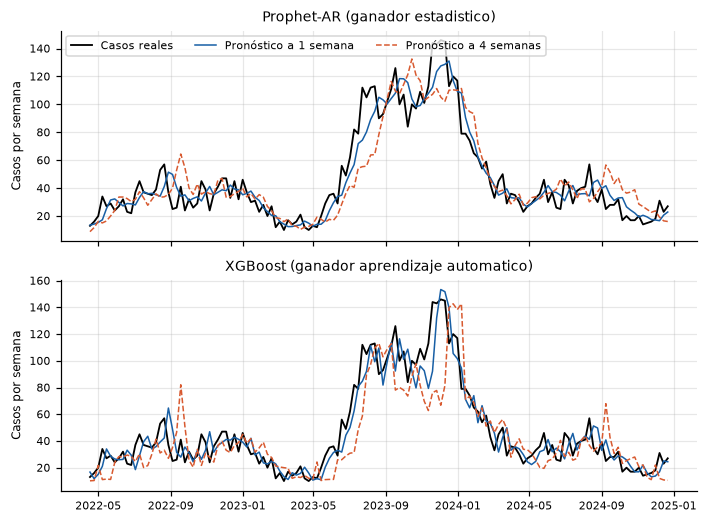

In [12]:
fig, axes = plt.subplots(len(GANADORES), 1, figsize=(6.5, 2.4 * len(GANADORES)), sharex=True)
for ax, (familia, ganador) in zip(np.atleast_1d(axes), GANADORES.items()):
    registros = REGISTROS_PRUEBA[ganador['clave']]
    reales = registros[registros['horizonte_semanas'] == 1].sort_values('fecha_objetivo')
    ax.plot(reales['fecha_objetivo'], reales['casos_reales'], color='black', lw=1.2, label='Casos reales')
    for h, color, ls in ((1, '#185FA5', '-'), (4, '#D85A30', '--')):
        parte = registros[registros['horizonte_semanas'] == h].sort_values('fecha_objetivo')
        ax.plot(parte['fecha_objetivo'], parte['pronostico_modelo'], color=color, ls=ls, lw=1.0,
                label=f'Pronóstico a {h} semana' + ('s' if h > 1 else ''))
    ax.set_title(f"{CANDIDATOS[ganador['clave']]['nombre']} (ganador {familia.replace('_', ' ')})")
    ax.set_ylabel('Casos por semana')
np.atleast_1d(axes)[0].legend(ncol=3, loc='upper left')
fig.tight_layout()
FIGURAS.guardar(fig, 'prueba_ganadores.png', 'Ganadores estadístico y de aprendizaje automático: casos reales de la prueba (abril de 2022 a diciembre de 2024) contra los pronósticos a 1 y 4 semanas')
plt.show()

## 5 Prueba final en 2025

Los ganadores se entrenan con 2007 a 2024 (modelo.entrenar) y pronostican desde cada semana de origen las 6 siguientes (modelo.pronosticar_trayectorias). Como en la prueba, los orígenes empiezan 6 semanas antes de 2025 para que cada horizonte tenga un registro por cada semana de 2025, y las métricas salen de evaluacion.metricas_desde_registros. 2025 tuvo un brote mayor que todo lo que los modelos conocían. Ningún resultado de esta prueba cambia una decisión.

14:04:43 - cmdstanpy - INFO - Chain [1] start processing


14:04:43 - cmdstanpy - INFO - Chain [1] done processing


Prophet-AR: RMSE global 2025 = 41.74 (persistencia 38.73) | registros = 318


XGBoost: RMSE global 2025 = 44.24 (persistencia 38.73) | registros = 318


,Modelo,H,RMSE,MAE,MAPE,R2,RMSE persistencia
0,Prophet-AR,1,23.159,13.243,14.415,0.871,16.518
1,Prophet-AR,2,30.207,16.871,17.325,0.781,26.994
2,Prophet-AR,3,37.418,19.976,19.774,0.664,35.392
3,Prophet-AR,4,43.876,23.613,22.980,0.537,42.084
4,Prophet-AR,5,50.624,28.348,27.351,0.384,47.391
5,Prophet-AR,6,55.823,31.971,31.070,0.251,52.241
6,XGBoost,1,34.768,20.269,20.403,0.710,16.518
7,XGBoost,2,36.413,21.618,21.564,0.681,26.994
8,XGBoost,3,39.436,25.273,25.848,0.626,35.392
9,XGBoost,4,44.119,28.931,29.803,0.532,42.084


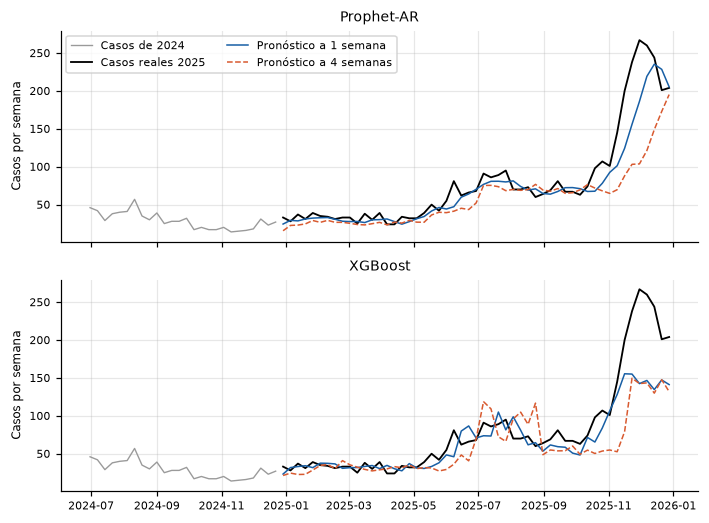

In [13]:
CRONO.etapa('prueba_final_2025')
PRUEBA_FINAL = {}
for familia, ganador in GANADORES.items():
    clave = ganador['clave']
    resultado = pr.prueba_final(pr.clase_modelo(clave), CANDIDATOS[clave]['hiperparametros'], SERIE, SEMANAS_2024)
    resultado['registros'].to_csv(SALIDAS.registros / f'06_{clave}_2025.csv', index=False, date_format='%Y-%m-%d')
    PRUEBA_FINAL[clave] = {'metricas': resultado['metricas'], 'registros': resultado['registros']}
    g = resultado['metricas']['global']
    print(f"{CANDIDATOS[clave]['nombre']}: RMSE global 2025 = {g['modelo']['RMSE']:.2f} "
          f"(persistencia {g['persistencia']['RMSE']:.2f}) | registros = {g['modelo']['n']}")

filas = []
for clave, datos in PRUEBA_FINAL.items():
    for h, bloque in datos['metricas']['por_horizonte'].items():
        filas.append({'Modelo': CANDIDATOS[clave]['nombre'], 'H': int(h),
                      **{m: bloque['modelo'][m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')},
                      'RMSE persistencia': bloque['persistencia']['RMSE']})
display(pd.DataFrame(filas).round(3))

contexto = SERIE.iloc[SEMANAS_2024 - 26:SEMANAS_2024]
fig, axes = plt.subplots(len(PRUEBA_FINAL), 1, figsize=(6.5, 2.4 * len(PRUEBA_FINAL)), sharex=True)
for ax, (clave, datos) in zip(np.atleast_1d(axes), PRUEBA_FINAL.items()):
    registros = datos['registros']
    ax.plot(contexto['fecha_semana'], contexto['casos'], color='#9a9a9a', lw=0.9, label='Casos de 2024')
    reales = registros[registros['horizonte_semanas'] == 1].sort_values('fecha_objetivo')
    ax.plot(reales['fecha_objetivo'], reales['casos_reales'], color='black', lw=1.2, label='Casos reales 2025')
    for h, color, ls in ((1, '#185FA5', '-'), (4, '#D85A30', '--')):
        parte = registros[registros['horizonte_semanas'] == h].sort_values('fecha_objetivo')
        ax.plot(parte['fecha_objetivo'], parte['pronostico_modelo'], color=color, ls=ls, lw=1.0,
                label=f'Pronóstico a {h} semana' + ('s' if h > 1 else ''))
    ax.set_title(CANDIDATOS[clave]['nombre'])
    ax.set_ylabel('Casos por semana')
np.atleast_1d(axes)[0].legend(ncol=2, loc='upper left')
fig.tight_layout()
FIGURAS.guardar(fig, 'prueba_final_2025.png', 'Prueba final 2025 de los ganadores estadístico y de aprendizaje automático: casos reales contra los pronósticos a 1 y 4 semanas')
plt.show()

## 6 Exportación al tablero

Para cada ganador, paquete.entrenar_evaluar_y_guardar con todo 2007-2025: evalúa en el 15 % final del rango (desde febrero de 2023), guarda pronosticos_prueba.csv y las métricas del manifest, y entrena el modelo definitivo con el 100 % del rango. paquete.exportar_zip lo empaqueta en outputs/paquetes/clave.zip. Después se descomprime una copia y se revisa con paquete.revisar_paquete, la misma revisión que hace el tablero al subirlo: formato, serie, librerías y versiones mayores, archivos, que las métricas del manifest se reconstruyan desde el CSV, y que el modelo cargue y pronostique.

In [14]:
CRONO.etapa('exportacion')
PAQUETES = {}
for familia, ganador in GANADORES.items():
    clave = ganador['clave']
    trabajo = Path(tempfile.mkdtemp(prefix=f'paquete_{clave}_'))
    manifest = paquete.entrenar_evaluar_y_guardar(clave, CANDIDATOS[clave]['hiperparametros'], SERIE,
                                                  trabajo / clave, USUARIO_TABLERO, ORIGEN_SUBIDO)
    ruta_zip = paquete.exportar_zip(trabajo / clave, SALIDAS.paquetes / f'{clave}.zip')
    revision = trabajo / 'revision'
    with zipfile.ZipFile(ruta_zip) as archivo_zip:
        archivo_zip.extractall(revision)
    revisado = paquete.revisar_paquete(revision, SERIE, USUARIO_TABLERO)
    (SALIDAS.paquetes / f'{clave}_manifest.json').write_text(
        (trabajo / clave / 'manifest.json').read_text(encoding='utf-8'), encoding='utf-8')
    shutil.rmtree(trabajo, ignore_errors=True)
    PAQUETES[clave] = {
        'zip': SALIDAS.relativa(ruta_zip), 'manifest': SALIDAS.relativa(SALIDAS.paquetes / f'{clave}_manifest.json'),
        'revision_tablero': 'aceptado', 'compatibilidad': revisado['compatibilidad'],
        'rango': manifest['rango'], 'prueba': manifest['prueba'], 'metricas_prueba': manifest['metricas_prueba'],
    }
    print(f"{clave}.zip aceptado por revisar_paquete | compatibilidad: {revisado['compatibilidad']}")

14:04:45 - cmdstanpy - INFO - Chain [1] start processing


14:04:45 - cmdstanpy - INFO - Chain [1] done processing


14:04:45 - cmdstanpy - INFO - Chain [1] start processing


14:04:45 - cmdstanpy - INFO - Chain [1] done processing


prophet_ar.zip aceptado por revisar_paquete | compatibilidad: {'prophet': {'exportado': '1.5.0', 'instalado': '1.5.0', 'estado': 'igual'}}


xgboost.zip aceptado por revisar_paquete | compatibilidad: {'xgboost': {'exportado': '3.4.1', 'instalado': '3.4.1', 'estado': 'igual'}}


## 7 Importancia de los hiperparámetros de los ganadores

Importancia relativa de cada hiperparámetro en la búsqueda de Optuna (fANOVA): qué parte de la variación del RMSE de validación cruzada explica cada uno.

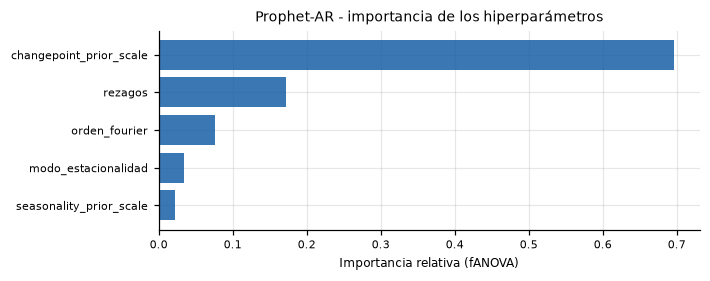

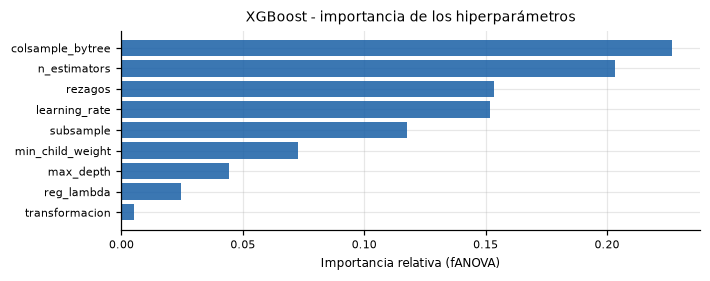

In [15]:
IMPORTANCIAS = {}
for familia, ganador in GANADORES.items():
    clave = ganador['clave']
    fig, valores = ex.figura_importancias(ESTUDIOS[clave], f"{CANDIDATOS[clave]['nombre']} - importancia de los hiperparámetros")
    IMPORTANCIAS[clave] = valores
    FIGURAS.guardar(fig, f'importancia_hiperparametros_{clave}.png',
                    f"Importancia de los hiperparámetros (fANOVA de Optuna) del ganador {CANDIDATOS[clave]['nombre']}")
    plt.show()

## 8 Resultados

outputs/resultados/06_resultados.json: todos los candidatos con sus hiperparámetros, la búsqueda de Optuna, la validación cruzada y las métricas de prueba H1 a H6 y globales; el ganador de cada familia y el criterio que decidió; la prueba final 2025 de los ganadores; y los paquetes exportados.

In [16]:
from datetime import datetime, timezone

CRONO.etapa('resultados')
RESULTADOS_06 = {
    'notebook': '06_produccion_estadisticos_ml',
    'modo_rapido': MODO_RAPIDO,
    'fecha': datetime.now(timezone.utc).isoformat(),
    'serie': 'tablero: construir_serie_semanal_departamental sobre dengue_consolidado.parquet',
    'periodos': PERIODOS,
    'validacion_cruzada': [{**k, 'inicio_fecha': fechas.iloc[k['inicio_bloque']], 'fin_fecha': fechas.iloc[k['fin_bloque'] - 1]}
                           for k in CORTES],
    'horizontes': ex.HORIZONTES,
    'pruebas_optuna': N_PRUEBAS,
    'diferenciacion': DIFERENCIACION,
    'candidatos': CANDIDATOS,
    'persistencia_prueba': {'global': PERSISTENCIA_PRUEBA['global']['persistencia'],
                            'por_horizonte': {h: v['persistencia'] for h, v in PERSISTENCIA_PRUEBA['por_horizonte'].items()}},
    'ganadores': GANADORES,
    'prueba_final_2025': {clave: datos['metricas'] for clave, datos in PRUEBA_FINAL.items()},
    'paquetes': PAQUETES,
    'importancias_hiperparametros': IMPORTANCIAS,
    'figuras': FIGURAS.figuras,
    'tiempos': CRONO.resumen(),
    'versiones': ex.versiones_librerias(['statsmodels', 'prophet', 'xgboost', 'lightgbm', 'optuna', 'pandas']),
}
ruta = ex.guardar_json(RESULTADOS_06, SALIDAS.resultados / '06_resultados.json')
print('Guardado:', ruta)
print('Tiempo total (s):', RESULTADOS_06['tiempos']['total_segundos'])

Guardado: C:\Users\elias\pruebas-eddie\dengue-surveillance-magdalena\outputs\resultados\06_resultados.json
Tiempo total (s): 3994.3


## 9 Conclusiones

Corrida completa del 7 de noviembre de 2026 en la máquina A (Intel Core i7-13650HX, 24 GB de RAM, NVIDIA RTX 5050; TensorFlow en CPU, PyTorch en GPU). Duración de este notebook: 67 minutos. Equipos y versiones: METODOLOGIA_PRONOSTICO.md, sección 13.

- Estadística: gana Prophet-AR (RMSE global 16,21; MAE 11,65; R² 0,768), por delante de SARIMA (18,27) y ARIMA (18,70). Es el único candidato de las dos familias que supera a la persistencia en la prueba (RMSE 18,12; razón 0,894), en los horizontes 2 a 6.
- Aprendizaje automático: gana XGBoost (RMSE global 20,15; MAE 13,47; R² 0,641) frente a LightGBM (20,90). Ninguno de los dos supera a la persistencia (razón 1,112 el ganador).
- Prueba final 2025: RMSE global de 41,74 para Prophet-AR y 44,24 para XGBoost, frente a 38,73 de la persistencia. En el brote de 2025, mayor que todo lo observado, ningún ganador supera a la persistencia; Prophet-AR queda entre un 4 % y un 7 % por encima de ella de H3 a H6.
- Los dos paquetes (prophet_ar.zip y xgboost.zip) pasan paquete.revisar_paquete, la revisión del tablero al subirlos.